In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- 0. Prepare a Simple Dataset ---
# Let's create a small dataset of 10 houses.
# Feature: 'Size' in square feet.
# Target: 'Price' in thousands of dollars.
data = {
    'Size': [1400, 1600, 1700, 1875, 1100, 1550, 2350, 2450, 1425, 1700],
    'Price': [245, 312, 279, 308, 199, 219, 405, 324, 319, 255]
}
df = pd.DataFrame(data)

X = df[['Size']]
y = df['Price']

print("--- Initial Dataset ---")
print(df)
print("-" * 30, "\n")


--- Initial Dataset ---
   Size  Price
0  1400    245
1  1600    312
2  1700    279
3  1875    308
4  1100    199
5  1550    219
6  2350    405
7  2450    324
8  1425    319
9  1700    255
------------------------------ 



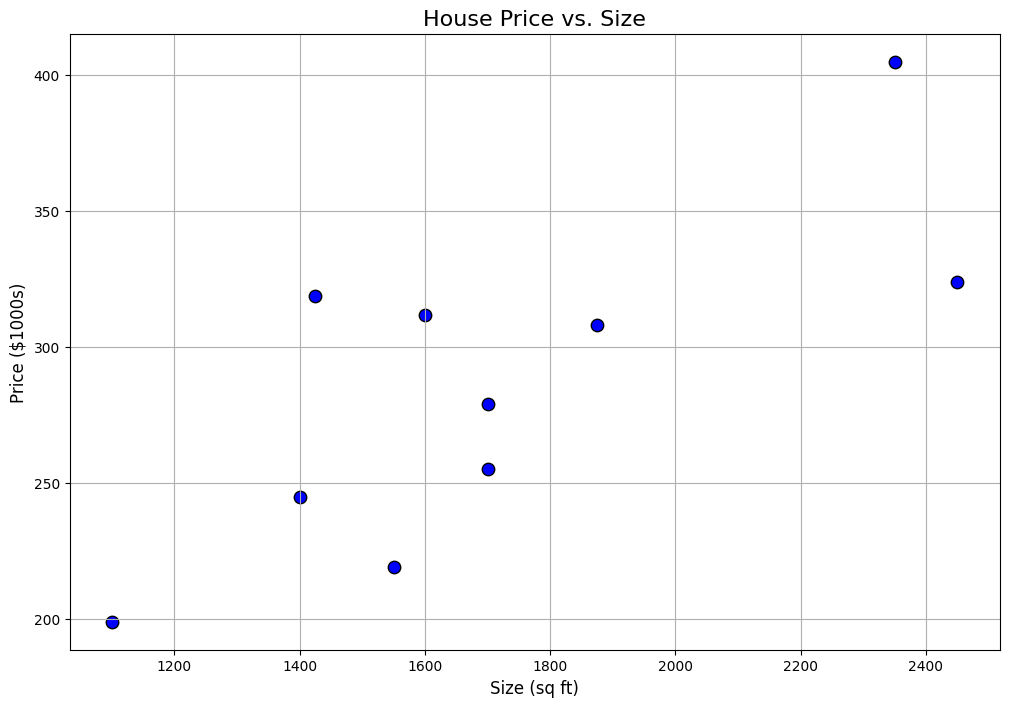

In [2]:

# --- Plot the Initial Dataset ---
plt.figure(figsize=(12, 8))
plt.scatter(X, y, color='blue', edgecolor='k', s=80)
plt.title('House Price vs. Size', fontsize=16)
plt.xlabel('Size (sq ft)', fontsize=12)
plt.ylabel('Price ($1000s)', fontsize=12)
plt.grid(True)
plt.show()


In [5]:


# In gradient boosting, we train new models on the "pseudo-residuals" of the
# previous model. Pseudo-residuals are the negative gradient (slope) of the
# loss function.
# For Mean Squared Error (MSE) loss, which is L = 1/2 * (y_true - y_pred)^2,
# the negative gradient is simply (y_true - y_pred).

#  Initialize the model with a constant value (F_0).
# The first prediction is the value that minimizes the total loss, which for MSE is the mean.
initial_prediction = y.mean()
df['F_0'] = initial_prediction

print(f"--- Round 0: Initial Prediction (F_0) ---")
print(f"The first prediction for all houses is the mean price: {initial_prediction:.2f}")

#  Compute pseudo-residuals for the initial model.
# For MSE loss, the pseudo-residual is just (Actual - Predicted).
df['Pseudo_Residual_0'] = y - df['F_0']
print("\nCompute initial pseudo-residuals (Negative Gradient of Loss Function)")
print("Note: For MSE loss, this is the same as (y - F_0)")
print(df[['Size', 'Price', 'F_0', 'Pseudo_Residual_0']].round(2))


--- Round 0: Initial Prediction (F_0) ---
The first prediction for all houses is the mean price: 286.50

Compute initial pseudo-residuals (Negative Gradient of Loss Function)
Note: For MSE loss, this is the same as (y - F_0)
   Size  Price    F_0  Pseudo_Residual_0
0  1400    245  286.5              -41.5
1  1600    312  286.5               25.5
2  1700    279  286.5               -7.5
3  1875    308  286.5               21.5
4  1100    199  286.5              -87.5
5  1550    219  286.5              -67.5
6  2350    405  286.5              118.5
7  2450    324  286.5               37.5
8  1425    319  286.5               32.5
9  1700    255  286.5              -31.5
